<a href="https://colab.research.google.com/github/nuralfiyanti/PCVK_Ganjil2026/blob/main/PCVKWEEK09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama  : Nur Alfiyanti

NIM   : 244107020055

Kelas : TI-3E

Modul 9 Morfologi (Erosi, Dilasi, Opening, Closing,
Transformasi Top-hat dan Bottom-hat, Skeleton, Thickening)

## **D. Praktikum**

**1. Buka https://colab.research.google.com/. Setelah dipastikan bahwa google Colab
terhubung dengan Github Anda, lanjutkan dengan memilih repository yang telah
digunakan pada praktikum minggu lalu, rename file menjadi “Week9.ipynb”.**

Kemudian import folder yang ada di Drive Anda dengan cara sebagai berikut.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**2. Import beberapa library berikut yang akan digunakan selama uji coba praktikum
minggu ke-6 berikut.**

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

**3. Dilasi tanpa library**

**Jobsheet: judul menyebut cross 3×3, tetapi kodenya memakai `np.ones((w,w))` dengan `w=5` (hasil contoh pada jobsheet berasal dari kode ini).**

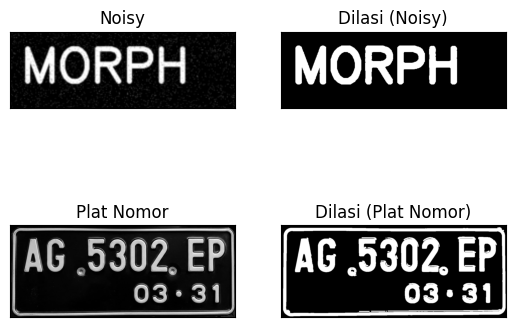

In [10]:

# Dilasi tanpa library

def dilasi_citra(F,w):
  # size image
  p,q = F.shape

  imgD = np.zeros((p,q), dtype=np.uint8)

  # Generate structure element dilasi (SED)
  SED = np.ones((w,w), dtype=np.uint8)
  constant1 = (w-1)//2

  # Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1, q-constant1):
      temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product = temp*SED
      imgD[i,j] = np.max(product)

  return imgD


img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png',0)
ret, thresh = cv2.threshold(img_noisy, 125, 200, cv2.THRESH_BINARY)
w = 5
imgN = dilasi_citra(thresh,w)

img_plat = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg',0)
ret, thresh_plat = cv2.threshold(img_plat, 125, 200, cv2.THRESH_BINARY)
w = 5
imgP = dilasi_citra(thresh_plat,w)

plt.subplot(2,2,1),plt.imshow(img_noisy,cmap='gray')
plt.title('Noisy'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,2),plt.imshow(imgN,cmap='gray')
plt.title('Dilasi (Noisy)'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,3),plt.imshow(img_plat,cmap='gray')
plt.title('Plat Nomor'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,4),plt.imshow(imgP,cmap='gray')
plt.title('Dilasi (Plat Nomor)'), plt.xticks([]), plt.yticks([])

plt.show()

**4. Buatlah program implementasi operasi dilasi Structuring Element Dilasi (SED)
berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV,
sehingga menghasilkan tampilan seperti di bawah ini:**

[[1 1 1]
 [1 1 1]
 [1 1 1]]
[[1 1 1]
 [1 1 1]
 [1 1 1]]


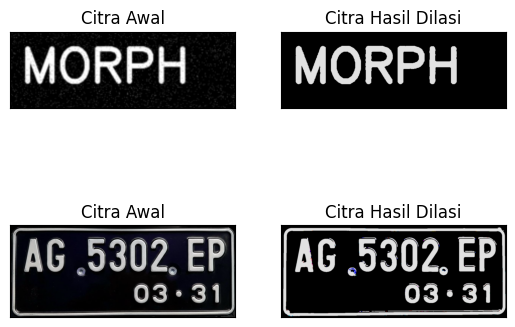

In [4]:

img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png')
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg')
#img = cv2.imread('morp.jpg',0)
ret, thresh_noisy = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi_noisy = cv2.dilate(thresh_noisy,kernel,iterations = 1)
print(kernel)

ret, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi_plat = cv2.dilate(thresh_plat,kernel,iterations = 1)
print(kernel)

plt.subplot(2,2,1),plt.imshow(img_noisy),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(2,2,2),plt.imshow(dilasi_noisy),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])

plt.subplot(2,2,3),plt.imshow(img_plat),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(2,2,4),plt.imshow(dilasi_plat),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])

plt.show()
plt.show()

**5. Buatlah fungsi erosi serta tampilkan hasil erosi pada citra dengan Structuring Element
Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari
openCV, sehingga menghasilkan tampilan seperti di bawah ini:**

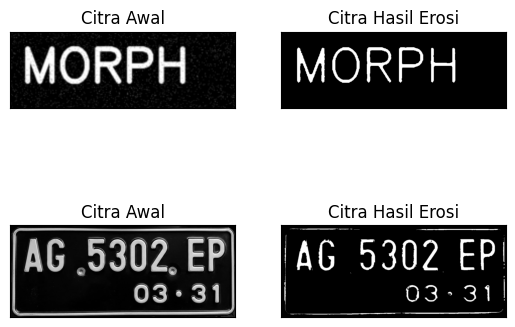

In [5]:
#Erosi Tanpa Library

def erosi_citra(F,k):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2

  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE

img_noisy= cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png',0) #
ret1, thresh_noisy = cv2.threshold(img_noisy, 175, 225, cv2.THRESH_BINARY)
k=5
imgN = erosi_citra(thresh_noisy,k)

img_plat= cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg',0) #
ret1, thresh_plat = cv2.threshold(img_plat, 175, 225, cv2.THRESH_BINARY)
k=5
imgP = erosi_citra(thresh_plat,k)

plt.subplot(2,2,1),plt.imshow(img_noisy,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,2),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,3),plt.imshow(img_plat,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,4),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()


**6. Buatlah program implementasi operasi dilasi Structuring Element Erosi (SE) berbentuk
square 5 x 5 dengan menggunakan library morphology dari openCV, sehingga
menghasilkan tampilan seperti di bawah ini:**


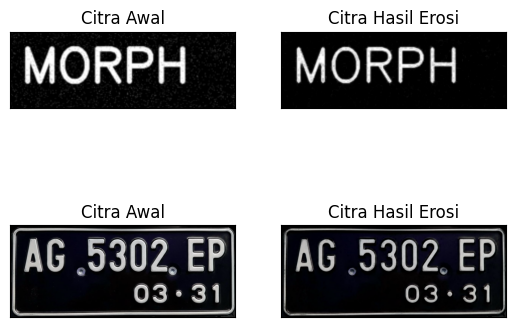

In [6]:
#EROSI LIBRARY
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png')
img_plat = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg')

kernel = np.ones((5,5),np.uint8)
erosionN = cv2.erode(img_noisy,kernel,iterations = 1)

kernel = np.ones((5,5),np.uint8)
erosionP = cv2.erode(img_plat,kernel,iterations = 1)

plt.subplot(2,2,1),plt.imshow(img_noisy),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(2,2,2),plt.imshow(erosionN),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])

plt.subplot(2,2,3),plt.imshow(img_plat),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(2,2,4),plt.imshow(erosionP),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])

plt.show()


**7. Buatlah program implementasi operasi opening dengan Structuring Element berbentuk square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV, sehingga menghasilkan tampilan seperti di bawah ini:**


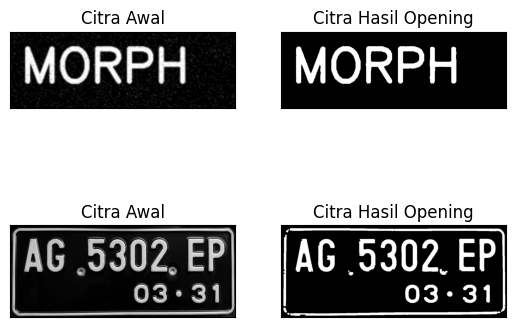

In [7]:

img_noisy= cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png',0) #
reto, thresho_noisy = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)
k=7
imgN = dilasi_citra(erosi_citra(thresho_noisy,k),k)

img_plat= cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg',0) #
reto, thresho_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
k=7
imgP = dilasi_citra(erosi_citra(thresho_plat,k),k)

plt.subplot(2,2,1),plt.imshow(img_noisy,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,2),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,3),plt.imshow(img_plat,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,4),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.show()

**Operasi Opening Menggunakan Library Morphology**

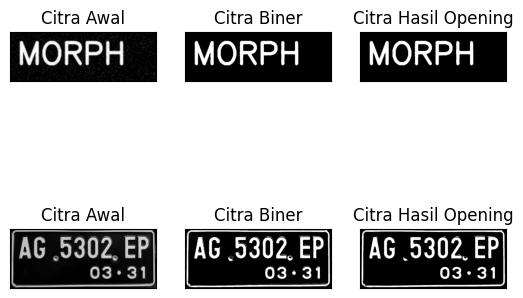

In [11]:

#Dengan Menggunakan Library
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png', 0)
ret, thresh_noisy = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
opennN = cv2.morphologyEx(thresh_noisy,cv2.MORPH_OPEN, kernel)

img_plat  = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
opennP = cv2.morphologyEx(thresh_plat,cv2.MORPH_OPEN, kernel)

plt.subplot(2,3,1),plt.imshow(img_noisy,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(2,3,2),plt.imshow(thresh_noisy,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

plt.subplot(2,3,3),plt.imshow(opennN,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.subplot(2,3,4),plt.imshow(img_plat,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(2,3,5),plt.imshow(thresh_plat,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

plt.subplot(2,3,6),plt.imshow(opennP,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.show()

**8. Buatlah program implementasi operasi closing dengan Structuring Element berbentuk
square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV,
sehingga menghasilkan tampilan seperti di bawah ini:
operasi closing tanpa library morphology**

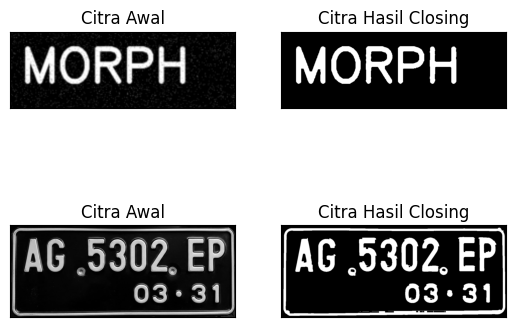

In [14]:
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png', 0)
ret, thresh_noisy = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)
k=7
imgN = erosi_citra(dilasi_citra(thresh_noisy,k),k)   #

img_plat = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
k=7
imgP = erosi_citra(dilasi_citra(thresh_plat,k),k)

plt.subplot(2,2,1),plt.imshow(img_noisy,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,2),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,3),plt.imshow(img_plat,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,4),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.show()

**operasi closing dengan library morphology**

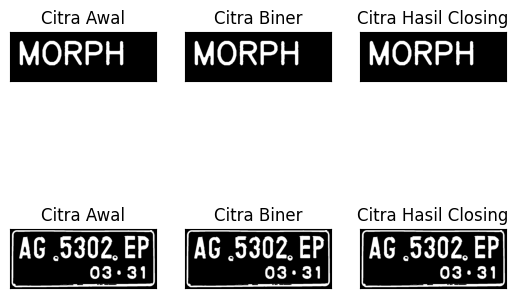

In [16]:
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png', 0)
ret, threshN = cv2.threshold(imgN, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
clossN = cv2.morphologyEx(threshN,cv2.MORPH_CLOSE, kernel)

img_plat = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret, threshP = cv2.threshold(imgP, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
clossP = cv2.morphologyEx(threshP,cv2.MORPH_CLOSE, kernel)

plt.subplot(2,3,1),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(2,3,2),plt.imshow(threshN,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

plt.subplot(2,3,3),plt.imshow(clossN,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.subplot(2,3,4),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(2,3,5),plt.imshow(threshP,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

plt.subplot(2,3,6),plt.imshow(clossP,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.show()

**9. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk Cross 3 x 3 dan 5 x 5, sehingga menghasilkan tampilan seperti di bawah ini:**

SED = Cross 3


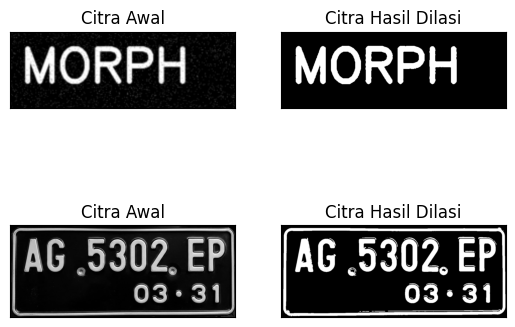

In [21]:
#Dilasi Cross SED

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)
  #Generate structure element dilasi (SED)
  SED = np.array([[0, 1, 0],
                  [1, 1, 1],
                  [0, 1, 0]], dtype = np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

print('SED = Cross 3')
img_noisy = cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png', 0)
img_plat  = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)

ret, threshN = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)
w=3
imgN = dilasi_citra(threshN,w)

ret, threshP = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
w=3
imgP = dilasi_citra(threshP,w)

plt.subplot(2,2,1),plt.imshow(img_noisy,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,2),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,3),plt.imshow(img_plat,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,4),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 5


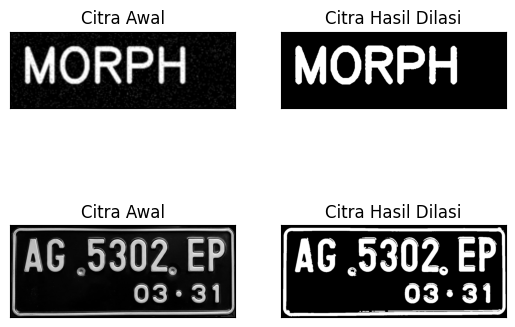

In [25]:
def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED = np.array([[0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0],
                  [1, 1, 1, 1, 1],
                  [0, 0, 1, 0, 0],
                  [0, 0, 1, 0, 0]], dtype = np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

print('SED = Cross 5')
img_N= cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png', 0)
img_P= cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)

ret, threshN = cv2.threshold(img_noisy, 127, 225, cv2.THRESH_BINARY)
w=5
imgN = dilasi_citra(threshN,w)

ret, threshP = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
w=5
imgP = dilasi_citra(threshP,w)

plt.subplot(2,2,1),plt.imshow(img_noisy,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,2),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,3),plt.imshow(img_plat,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,4),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

**10. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk
Circular 3 x 3 dan 5 x 5, sehingga menghasilkan tampilan seperti di bawah ini:**

SED = Circle 3


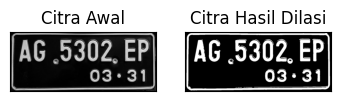

In [23]:
#Dilasi Circular SED

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD
print('SED = Circle 3')
img_N= cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png',0)
ret, thresh = cv2.threshold(img_N, 127, 225, cv2.THRESH_BINARY)
w=3
imgN = dilasi_citra(thresh,w)

img_P= cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg',0)
ret, thresh = cv2.threshold(img_P, 127, 225, cv2.THRESH_BINARY)
w=3
imgP = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_N,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.subplot(131),plt.imshow(img_P,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.show()


SED = Circle 5


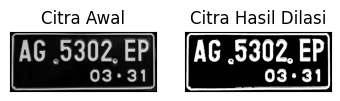

In [24]:
print('SED = Circle 5')
img_N= cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png',0)
ret, thresh = cv2.threshold(img_N, 127, 225, cv2.THRESH_BINARY)
w=5
imgN = dilasi_citra(thresh,w)

img_P= cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg',0)
ret, thresh = cv2.threshold(img_P, 127, 225, cv2.THRESH_BINARY)
w=5
imgP = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_N,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.subplot(131),plt.imshow(img_P,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.show()

**11. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk
Rectangle 3 x 5 dan 5 x 7, sehingga menghasilkan tampilan seperti di bawah ini:**

SE = Rectangle 3x5


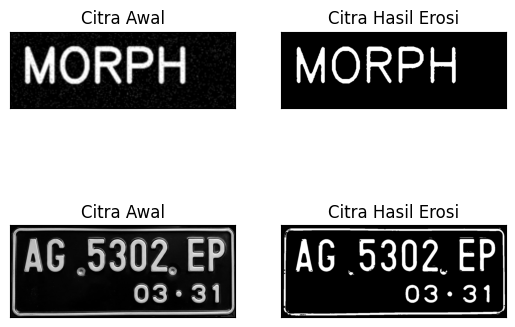

SE = Rectangle 5x7


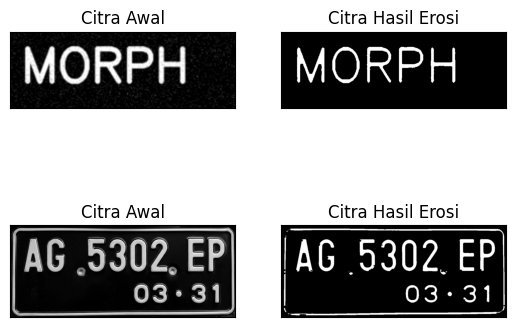

In [27]:
#Erosi Cross SE

def erosi_citra(F,p,l):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l)) #SE persegi panjang
  constant1= (l-1)//2
  constant2= (p-1)//2
  # print(SE)
  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant1, m-constant1):
    for j in range(constant2,n-constant2):
      temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE
print('SE = Rectangle 3x5')
img_N= cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png',0) #
ret1, thresh1 = cv2.threshold(img_N, 127, 225, cv2.THRESH_BINARY)
p=5
l=3
imgN = erosi_citra(thresh1,p,l)

img_P= cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg',0) #
ret1, thresh1 = cv2.threshold(img_P, 127, 225, cv2.THRESH_BINARY)
p=5
l=3
imgP = erosi_citra(thresh1,p,l)

plt.subplot(2,2,1),plt.imshow(img_N,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,2),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,3),plt.imshow(img_P,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,4),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()

print('SE = Rectangle 5x7')
img_N= cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png',0) #
ret1, thresh1 = cv2.threshold(img_N, 127, 225, cv2.THRESH_BINARY)
p=7
l=5
imgN = erosi_citra(thresh1,p,l)

img_P= cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg',0) #
ret1, thresh1 = cv2.threshold(img_P, 127, 225, cv2.THRESH_BINARY)
p=7
l=5
imgP = erosi_citra(thresh1,p,l)

plt.subplot(2,2,1),plt.imshow(img_N,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,2),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.subplot(2,2,3),plt.imshow(img_P,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,4),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()

**12. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk
Line Vertikal 3 dan 5, sehingga menghasilkan tampilan seperti di bawah ini: (Gunakan
gambar j.png)**

SE = Line Vertikal 3


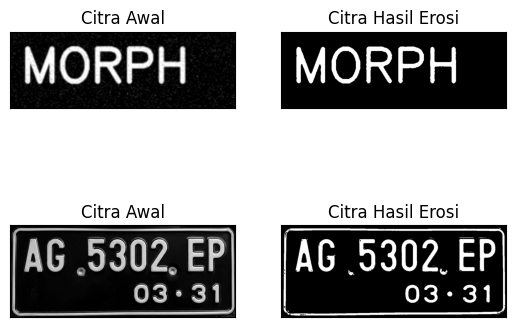

SE = Line Vertikal 5


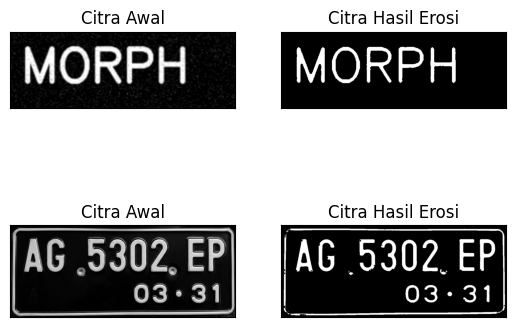

In [28]:
#Erosi Line Vertikal SE

def erosi_citra(F,k):
  #size image
  m,n= F.shape

  #Generate structure element erosi (SE)
  SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k)) #SE line vertikal
  constant= (k-1)//2

  imgE= np.zeros((m,n), dtype=np.uint8)

  #Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE
print('SE = Line Vertikal 3')
img_N= cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png',0) #
ret1, thresh1 = cv2.threshold(img_N, 127, 225, cv2.THRESH_BINARY)
k=3
imgN = erosi_citra(thresh1,k)

img_P= cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg',0) #
ret1, thresh1 = cv2.threshold(img_P, 127, 225, cv2.THRESH_BINARY)
k=3
imgP = erosi_citra(thresh1,k)

plt.subplot(221),plt.imshow(img_N,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.subplot(223),plt.imshow(img_P,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()

print('SE = Line Vertikal 5')
img_N= cv2.imread('/content/drive/MyDrive/PCVK/noisy_text.png',0) #
ret1, thresh1 = cv2.threshold(img_N, 127, 225, cv2.THRESH_BINARY)
k=5
imgN = erosi_citra(thresh1,k)

img_P= cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg',0) #
ret1, thresh1 = cv2.threshold(img_P, 127, 225, cv2.THRESH_BINARY)
k=5
imgP = erosi_citra(thresh1,k)

plt.subplot(221),plt.imshow(img_N,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222),plt.imshow(imgN,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.subplot(223),plt.imshow(img_P,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224),plt.imshow(imgP,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()

**13. TopHat**

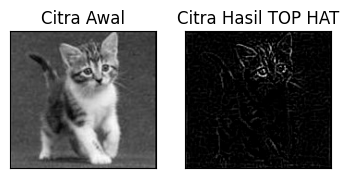

In [37]:
# Getting the kernel to be used in Top-Hat
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,
                filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

**14. BLACKHAT**

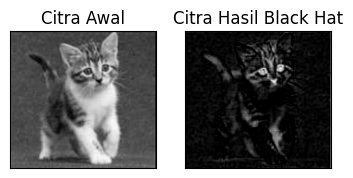

In [36]:

filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
#tophat_img = cv2.morphologyEx(img,cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)
#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

**15. Skeleton**

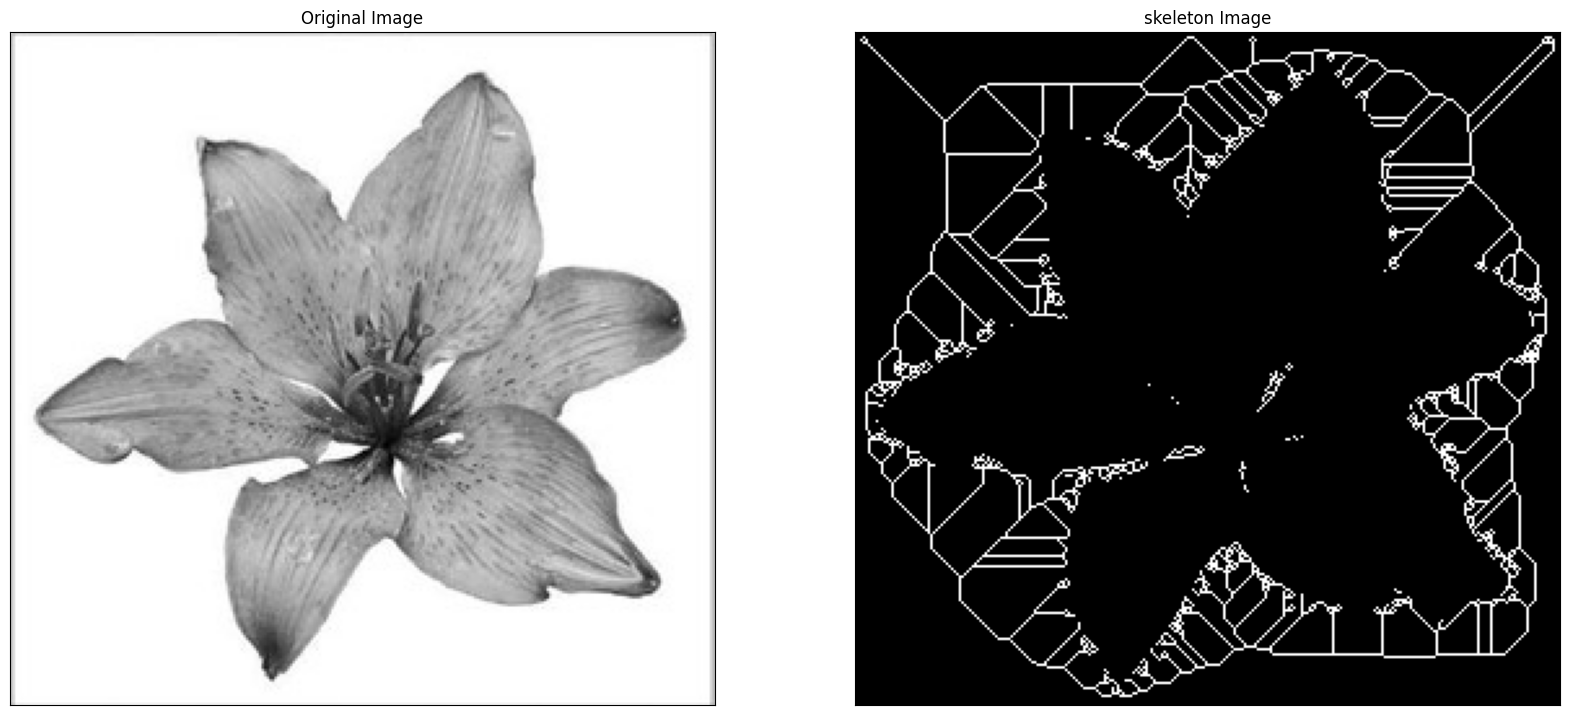

In [38]:

import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread('/content/drive/MyDrive/PCVK/lily.jpg',0)

binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20,20))

plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()


**16. Skeleton Inverse**

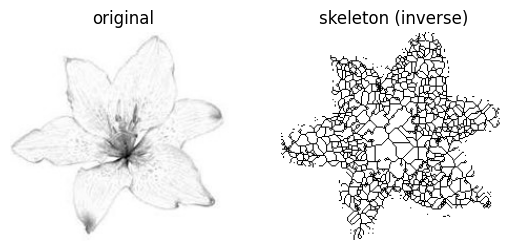

In [41]:

from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread('/content/drive/MyDrive/PCVK/lily01.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

**17. Buatlah program thinning memakai morphology.thin(), lalu bandingkan hasilnya dengan skeleton pada langkah 15.**

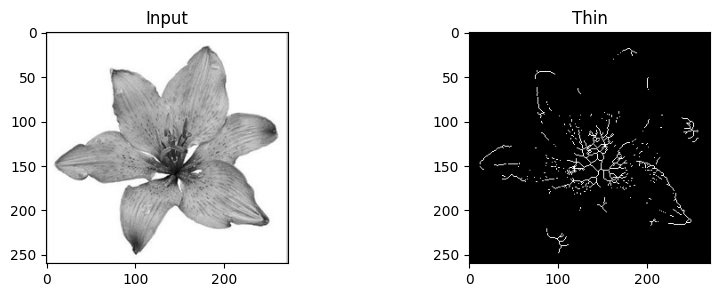

In [42]:

from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()
